# Reconstruction vs contrastive vs prediction

The pre-registered design, the hypotheses and their thresholds are in `experiments/recon_vs_pred/README.md`, which was written before any learner was trained and amended, pilot-informed, before HPC training (H1 = single-window MLP probe, H2 = MLP nuisance probe, H3a legacy / H3b primary, fresh evaluation series, CPC pre-declared as failed to train).

**Question.** Does a prediction objective keep a dynamical regime that a reconstruction objective loses? If so, is the reason that it drops what it cannot predict?

**Manipulation.** One regime-independent nuisance is added to the observation. Its timescale is either fast (weak start-to-start correlation; residual predictability across the gap) or slow (persists into the target), at amplitude σ_n = 1 or 2, plus a no-nuisance condition N0.

This notebook only *displays* results that were computed elsewhere:
- `python experiments/recon_vs_pred/run.py pilot` runs the local, exploratory pilot;
- `python experiments/recon_vs_pred/run.py hpc <runs dir>` scores the confirmatory HPC sweep.

Set `MODE` to choose which results are shown.

In [1]:
import os, sys
import numpy as np, pandas as pd, matplotlib.pyplot as plt
sys.path.insert(0, "experiments/recon_vs_pred")
import cpbench
from cpbench.data import Dataset
from design import CONDITIONS, dataset, W
from experiment import verdicts, PRED, RECON, PROTOCOL
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110, "font.size": 9})
pd.set_option("display.width", 220); pd.set_option("display.max_colwidth", 120)

MODE = os.environ.get("CPBENCH_MODE", "pilot")      # ✏️ "pilot" (exploratory) or "hpc" (confirmatory)
df = pd.read_csv(f"cpbench_results/recon_vs_pred_{MODE}.csv")
print(MODE, len(df), "rows;", sorted(df.cond.unique()), "seeds", sorted(df.seed.unique()), "protocol", sorted(df.protocol.unique()))
assert df.protocol.nunique() == 1, "mixed scoring protocols are never pooled"
RET = "probe_mlp_single" if "probe_mlp_single" in df else "probe"          # H1 primary (legacy pilot CSV: linear probe)
NUIS = "nuis_mlp_r2" if "nuis_mlp_r2" in df else "nuis_r2"                 # H2 primary (legacy pilot CSV: ridge)

hpc 110 rows; ['F1', 'F2', 'N0', 'S1', 'S2'] seeds [np.int64(0), np.int64(1), np.int64(2)] protocol ['audit_v2+pilot_informed_v1']


## 1. The data

Each panel shows the first 400 samples of three of the 64 channels in one condition. The coloured band marks the regime. The nuisance is invisible in N0, wiggles quickly in F2 and drifts slowly in S2.

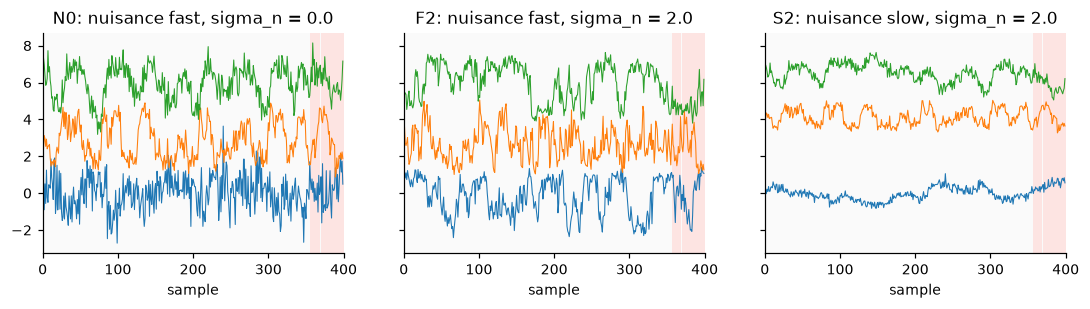

In [2]:
fig, axes = plt.subplots(1, 3, figsize=(12, 2.6), sharey=True)
for ax, c in zip(axes, ("N0", "F2", "S2")):
    d = Dataset(dataset(c, quick=True)).sample(1, 1200, np.random.default_rng(0))
    for j in range(3):
        ax.plot(d["obs"][0, :400, j] + 3 * j, lw=0.7)
    ax.pcolorfast((0, 400), ax.get_ylim(), d["S_s"][:, :400], cmap="Pastel1", alpha=0.35)
    ax.set_title(f"{c}: nuisance {CONDITIONS[c][0]}, sigma_n = {CONDITIONS[c][1]}"); ax.set_xlabel("sample")
plt.show()

## 2. Verdicts (pre-registered thresholds)

In pilot mode these verdicts are exploratory: one seed and 3k steps. Only the HPC run decides H1, H2, H3a (legacy), H3b and H4 (exploratory). Rows marked `secondary`, `exploratory` or `info` decide nothing. Under the pilot CSV (legacy protocol) the completeness gate cannot pass.

In [3]:
verdicts(df, confirmatory=MODE == "hpc")

,test,verdict,numbers
0,gate: complete confirmatory protocol,pass,"missing=0, duplicates=False, finite=True, budget=True, protocol=True, fresh eval series=True"
1,gate: oracle HMM acc >= 0.95 everywhere,pass,"N0 0.959, F1 0.959, F2 0.959, S1 0.959, S2 0.959"
2,gate: some trained learner has probe >= 0.9 on N0,pass,best mean linear probe 0.981 (jepa_shared)
3,"gate: no collapse (eff_rank > 2, final loss < loss at 1k; excl. pre-declared cpc)",pass,-
4,"reported: pre-declared failed-to-train methods (cpc), collapse criterion",info,0/15 runs fail it: -
5,control F1: family probe_mlp_single - untrained (0.609) >= 0.05,info,"pred +0.352: keeps regime, recon +0.330: keeps regime"
6,control F1: family probe - untrained (0.605) >= 0.05,info,"pred +0.369: keeps regime, recon -0.049: does not meet retention criterion"
7,control F2: family probe_mlp_single - untrained (0.548) >= 0.05,info,"pred +0.420: keeps regime, recon +0.399: keeps regime"
8,control F2: family probe - untrained (0.540) >= 0.05,info,"pred +0.433: keeps regime, recon +0.046: does not meet retention criterion"
9,control N0: family probe_mlp_single - untrained (0.714) >= 0.05,info,"pred +0.249: keeps regime, recon +0.243: keeps regime"


## 3. All numbers (mean ± sd over seeds)

| Column | What it measures | Reference |
|---|---|---|
| `probe_mlp_single` | fixed MLP probe of the regime on single windows, **H1 primary** | chance 0.5 |
| `probe` | linear probe of the regime, secondary | chance 0.5 |
| `probe_mlp_pair` | MLP probe on window pairs, secondary | chance 0.5 |
| `nuis_mlp_r2` | fixed MLP decoding of nuisance coordinates, **H2 primary** | 0 = test-mean baseline; negative values retained |
| `nuis_r2` | ridge decoding of nuisance coordinates, secondary | as above |
| `hmm` | unsupervised clustering accuracy, primary (H3a, H3b) | — |
| `gmm` | unsupervised clustering accuracy, secondary | — |


In [4]:
cols = [c for c in ["probe_mlp_single", "probe", "probe_mlp_pair", "probe_mlp", "nuis_mlp_r2", "nuis_r2", "hmm", "gmm"] if c in df]
order = ["ae", "vae", "jepa_separate", "jepa_shared", "cpc", "ts2vec", "untrained", "raw_flat", "raw_lagcov", "oracle"]
g = df.groupby(["cond", "learner"])[cols]
tab = g.mean().round(3).astype(str) + np.where(g.count() > 1, " ± " + g.std().round(2).astype(str), "")
tab = tab.reset_index().pivot(index="learner", columns="cond").reindex(order).dropna(how="all")
tab

probe_mlp_single                                                                 probe                                                          ...          hmm                                           \
cond                        F1            F2            N0            S1            S2            F1            F2            N0            S1            S2  ...           F1            F2           N0            S1   
learner                                                                                                                                                       ...                                                         
ae                0.954 ± 0.01  0.947 ± 0.01   0.952 ± 0.0  0.909 ± 0.03  0.906 ± 0.03  0.539 ± 0.03  0.599 ± 0.01  0.507 ± 0.02   0.563 ± 0.0  0.552 ± 0.02  ...  0.968 ± 0.0   0.966 ± 0.0  0.968 ± 0.0   0.507 ± 0.0   
vae               0.923 ± 0.02  0.947 ± 0.02  0.962 ± 0.01  0.924 ± 0.02    0.92 ± 0.0  0.573 ± 0.03  0.575 ± 0.06  0.527 ± 0.01   0.563 ± 0.0  0.542 ± 0.02  ...  0.967 ± 0.0   0.967 ± 0.0  0.968 ± 0.0  0.528 ± 0.01   
jepa_separate     0.954 ± 0.01   0.961 ± 0.0  0.956 ± 0.01  0.911 ± 0.02  0.936 ± 0.02   0.966 ± 0.0   0.966 ± 0.0   0.964 ± 0.0  0.958 ± 0.01   0.962 ± 0.0  ...  0.962 ± 0.0   0.962 ± 0.0  0.961 ± 0.0  0.685 ± 0.24   
jepa_shared       0.968 ± 0.01  0.974 ± 0.01   0.971 ± 0.0  0.962 ± 0.01  0.971 ± 0.01   0.982 ± 0.0   0.981 ± 0.0   0.981 ± 0.0   0.982 ± 0.0  0.979 ± 0.01  ...  0.969 ± 0.0   0.969 ± 0.0   0.97 ± 0.0  0.659 ± 0.27   
cpc               0.955 ± 0.02  0.956 ± 0.01  0.949 ± 0.03  0.925 ± 0.04  0.534 ± 0.02    0.97 ± 0.0   0.969 ± 0.0   0.968 ± 0.0  0.938 ± 0.04   0.52 ± 0.02  ...  0.961 ± 0.0   0.961 ± 0.0  0.961 ± 0.0  0.543 ± 0.02   
ts2vec            0.886 ± 0.01  0.883 ± 0.02   0.83 ± 0.01  0.847 ± 0.02   0.89 ± 0.02  0.909 ± 0.01  0.875 ± 0.02  0.805 ± 0.04  0.827 ± 0.04  0.879 ± 0.01  ...  0.951 ± 0.0  0.947 ± 0.01  0.952 ± 0.0  0.545 ± 0.01   
untrained                0.609         0.548         0.714         0.616         0.579         0.605          0.54         0.748           0.6         0.564  ...        0.513           0.5         0.57         0.502   
raw_flat                 0.932         0.881         0.965         0.942         0.939         0.525          0.52         0.476         0.523         0.533  ...        0.503          0.51         0.97         0.511   
raw_lagcov               0.987         0.983         0.987         0.986         0.985         0.986         0.985         0.982         0.982         0.982  ...        0.972         0.971        0.972         0.971   
oracle                   0.974         0.974         0.974         0.974         0.974          0.98          0.98          0.98          0.98          0.98  ...        0.959         0.959        0.959         0.959   

                                      gmm                                                          
cond                     S2            F1            F2            N0            S1            S2  
learner                                                                                            
ae              0.505 ± 0.0   0.962 ± 0.0  0.954 ± 0.01   0.968 ± 0.0  0.518 ± 0.01   0.508 ± 0.0  
vae            0.533 ± 0.04    0.96 ± 0.0  0.838 ± 0.21   0.968 ± 0.0  0.541 ± 0.03  0.515 ± 0.01  
jepa_separate   0.53 ± 0.01   0.961 ± 0.0   0.82 ± 0.25   0.961 ± 0.0  0.685 ± 0.24  0.536 ± 0.01  
jepa_shared    0.552 ± 0.02   0.969 ± 0.0   0.969 ± 0.0    0.97 ± 0.0  0.679 ± 0.25   0.536 ± 0.0  
cpc            0.533 ± 0.02    0.96 ± 0.0   0.961 ± 0.0   0.961 ± 0.0  0.536 ± 0.01  0.542 ± 0.01  
ts2vec          0.523 ± 0.0  0.888 ± 0.04  0.867 ± 0.03  0.859 ± 0.04  0.543 ± 0.02   0.524 ± 0.0  
untrained             0.512         0.508         0.507         0.562           0.5         0.511  
raw_flat              0.549         0.501         0.514         0.968         0.521         0.546  
raw_lagcov            0.971         0.971         0.971         0.

## 4. What each learner keeps

Each point is one run. The x-axis shows nuisance decodability and the y-axis regime retention, both with the primary (MLP) probes.

Hypothesis H2 predicts:
- **prediction** (JEPA) sits to the left in F2, if the fast nuisance becomes less accessible, and moves right in S2;
- **reconstruction** (AE, VAE) sits to the right in both.

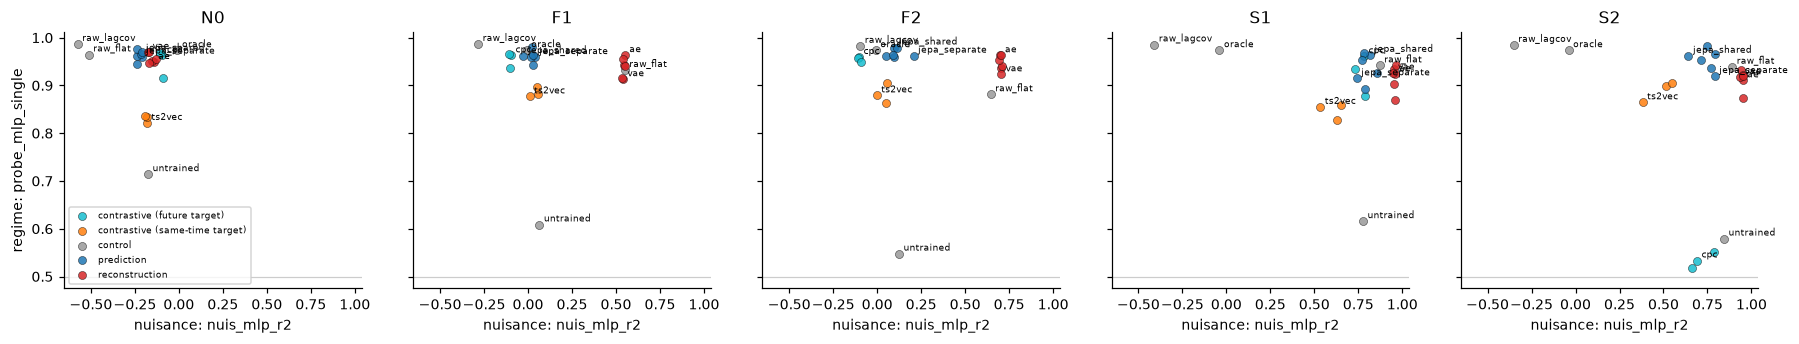

In [5]:
COL = {"reconstruction": "tab:red", "prediction": "tab:blue", "contrastive (future target)": "tab:cyan",
       "contrastive (same-time target)": "tab:orange", "control": "0.6"}
conds = [c for c in CONDITIONS if c in set(df.cond)]
fig, axes = plt.subplots(1, len(conds), figsize=(3.3 * len(conds), 3.2), sharey=True, sharex=True)
for ax, c in zip(np.atleast_1d(axes), conds):
    for fam, sub in df[df.cond == c].groupby("family"):
        ax.scatter(sub[NUIS], sub[RET], color=COL[fam], s=28, label=fam, alpha=0.85, edgecolor="k", lw=0.3)
        for r in sub.drop_duplicates("learner").itertuples():
            ax.annotate(r.learner, (getattr(r, NUIS), getattr(r, RET)), fontsize=6, xytext=(3, 2), textcoords="offset points")
    ax.axhline(0.5, color="0.8", lw=0.8); ax.set_title(c); ax.set_xlabel(f"nuisance: {NUIS}")
np.atleast_1d(axes)[0].set_ylabel(f"regime: {RET}"); np.atleast_1d(axes)[0].legend(fontsize=6, loc="lower left")
plt.tight_layout(); plt.show()

## 5. Retention versus clusterability

Each panel compares the regime probe (bars) with unsupervised HMM accuracy (black dots). A high probe with low HMM accuracy indicates information accessible to the probe but poorly recovered by this detector; it does not prove that every clustering method fails.

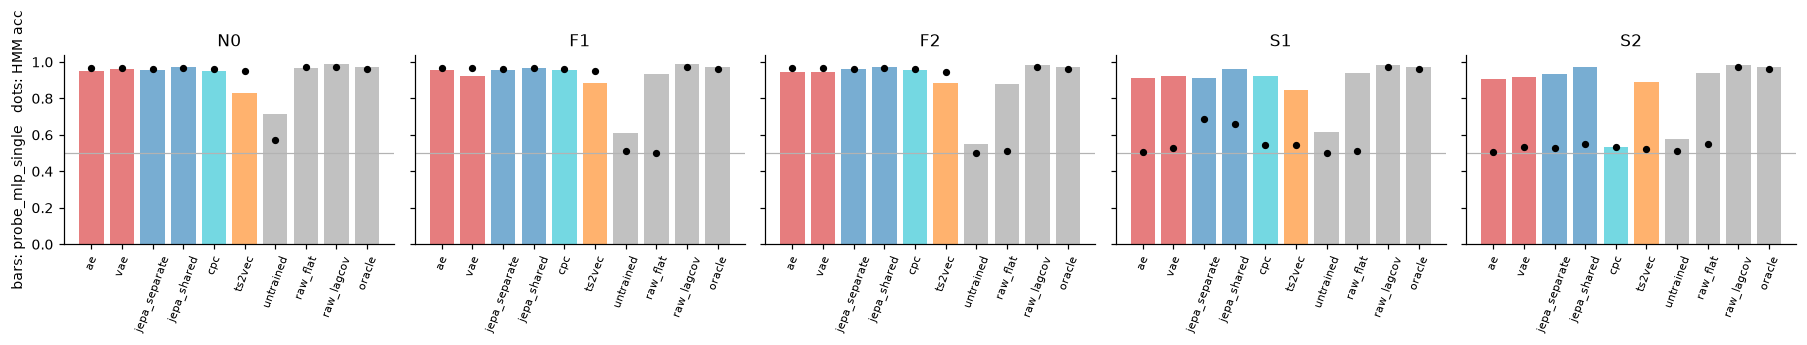

In [6]:
lead = [l for l in order if l in set(df.learner)]
fig, axes = plt.subplots(1, len(conds), figsize=(3.3 * len(conds), 3.0), sharey=True)
for ax, c in zip(np.atleast_1d(axes), conds):
    m = df[df.cond == c].groupby("learner")[[RET, "hmm"]].mean().reindex(lead)
    x = np.arange(len(m))
    ax.bar(x, m[RET], color=[COL[df[df.learner == l].family.iloc[0]] for l in m.index], alpha=0.6)
    ax.scatter(x, m.hmm, color="k", s=14, zorder=3)
    ax.set_xticks(x, m.index, rotation=70, fontsize=7); ax.axhline(0.5, color="0.7", lw=0.8); ax.set_title(c)
np.atleast_1d(axes)[0].set_ylabel(f"bars: {RET}   dots: HMM acc")
plt.tight_layout(); plt.show()

## 6. Dose response (needs all five conditions: the HPC run)

Each metric is plotted against the nuisance amplitude σ_n (0, 1, 2). Solid lines are fast nuisance and dashed lines slow nuisance.

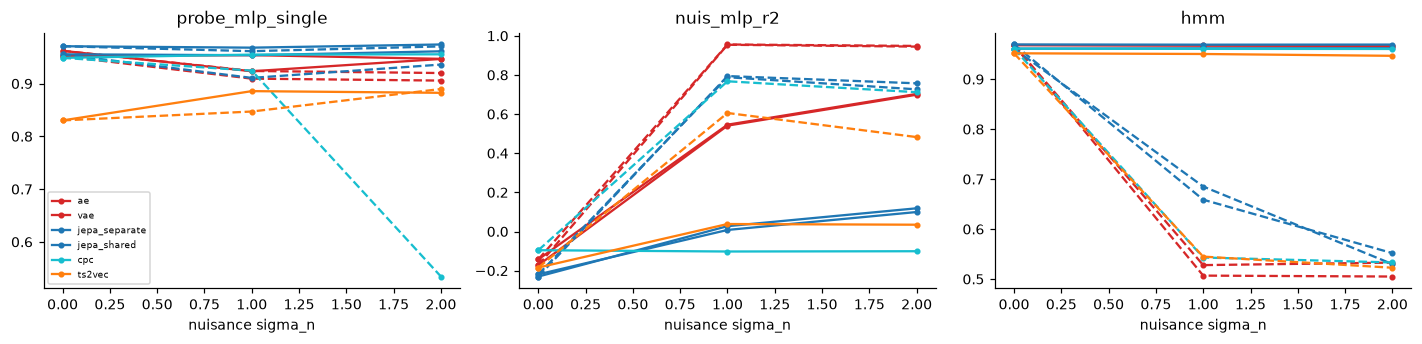

In [7]:
if set(CONDITIONS) <= set(df.cond):
    fig, axes = plt.subplots(1, 3, figsize=(13, 3.2))
    for ax, m in zip(axes, (RET, NUIS, "hmm")):
        for l in ["ae", "vae", "jepa_separate", "jepa_shared", "cpc", "ts2vec"]:
            fam = df[df.learner == l].family.iloc[0]
            for speed, ls in (("fast", "-"), ("slow", "--")):
                sub = df[(df.learner == l) & ((df.speed == speed) | (df.cond == "N0"))].groupby("sigma_n")[m].mean()
                ax.plot(sub.index, sub.values, ls, color=COL[fam], marker="o", ms=3, label=l if speed == "fast" else None)
        ax.set_xlabel("nuisance sigma_n"); ax.set_title(m)
    axes[0].legend(fontsize=6); plt.tight_layout(); plt.show()
else:
    print("pilot: only", conds)

## Amendments
Audit amendment: confirmatory verdicts require complete results and passing gates. Three paired training seeds on one fixed dataset seed quantify training variability only. TS2Vec uses its reference architecture; this is not an objective-only, equal-capacity comparison. CP metrics and nonlinear/paired nuisance diagnostics are secondary. HMM/GMM primary fits are selected by persistence.

Pilot-informed amendment (fixed before HPC training): H1 is decided by the single-window MLP probe and H2 by the MLP nuisance probe (linear/ridge secondary); H3 is split into H3a (legacy JEPA F2 vs S2) and H3b (F2 HMM, prediction vs reconstruction, paired by seed); the nuisance–clustering association is exploratory; evaluation series are fresh (`eval_seed`); CPC is pre-declared as failed to train. See experiments/recon_vs_pred/README.md.


In [8]:
secondary = [c for c in df.columns if "_cp_" in c or c in ("nuis_paired_distance", "hmm_fixed_acc", "gmm_fixed_acc", "parameters_total")]
if secondary:
    display(df.groupby(["cond", "learner"])[secondary].agg(["mean", "std"]))


hmm_cp_ap           hmm_cp_f1           hmm_cp_covering           hmm_cp_f1_best           gmm_cp_ap            ... gmm_cp_f1_best           parameters_total      nuis_paired_distance            \
                        mean       std      mean       std            mean       std           mean       std      mean       std  ...           mean       std             mean  std                 mean       std   
cond learner                                                                                                                       ...                                                                                 
F1   ae             0.611403  0.011937  0.510963  0.001812        0.588124  0.008464       0.722546  0.011685  0.608679  0.016649  ...       0.709442  0.011331        4632336.0  0.0             0.452281  0.012357   
     cpc            0.349806  0.003082  0.599037  0.009395        0.872953  0.012756       0.608242  0.005358  0.352270  0.003077  ...       0.604952  0.002744        2259984.0  0.0             0.017772  0.001104   
     jepa_separate  0.396834  0.020214  0.433833  0.014892        0.706039  0.022771       0.584153  0.009169  0.400167  0.012725  ...       0.586571  0.002225        2268192.0  0.0             0.732774  0.012232   
     jepa_shared    0.584797  0.006972  0.563607  0.009372        0.705039  0.009986       0.715438  0.009155  0.590589  0.012527  ...       0.718290  0.018622        2259984.0  0.0             0.758176  0.011937   
     oracle         0.497443       NaN  0.592417       NaN        0.812262       NaN       0.640827       NaN  0.617901       NaN  ...       0.722078       NaN              NaN  NaN             0.000000       NaN   
     raw_flat       0.025785       NaN  0.000000       NaN        0.071082       NaN       0.149010       NaN  0.025145       NaN  ...       0.152955       NaN              NaN  NaN             0.679460       NaN   
     raw_lagcov     0.686551       NaN  0.572477       NaN        0.615568       NaN       0.779487       NaN  0.693954       NaN  ...       0.786632       NaN              NaN  NaN             0.734123       NaN   
     ts2vec         0.438246  0.016899  0.471257  0.020736        0.641622  0.008103       0.577360  0.009578  0.314685  0.118851  ...       0.466521  0.092291         256112.0  0.0             0.717808  0.007163   
     untrained      0.023864       NaN  0.000000       NaN        0.071082       NaN       0.141119       NaN  0.027446       NaN  ...       0.143030       NaN        2259984.0  NaN             0.856748       NaN   
     vae            0.632335  0.016505  0.511988  0.010435        0.578768  0.013649       0.732301  0.007568  0.628803  0.018847  ...       0.726908  0.012425        4640544.0  0.0             0.586941  0.002242   
F2   ae             0.632655  0.021197  0.584906  0.009720        0.676020  0.022133       0.738832  0.007874  0.613831  0.016867  ...       0.704049  0.010494        4632336.0  0.0             0.735813  0.006043   
     cpc            0.348477  0.008417  0.592743  0.011601        0.869378  0.005759       0.604138  0.005257  0.350850  0.009001  ...       0.607261  0.007562        2259984.0  0.0             0.022407  0.000759   
     jepa_separate  0.402994  0.005262  0.439528  0.015032        0.699922  0.013029       0.586871  0.009189  0.289060  0.214614  ...       0.452450  0.249833        2268192.0  0.0             0.799124  0.021073   
     jepa_shared    0.588063  0.009707  0.553297  0.020351        0.689205  0.013451       0.723047  0.014045  0.612683  0.021268  ...       0.740319  0.008810        2259984.0  0.0             0.826295  0.013396   
     oracle         0.497443       NaN  0.592417       NaN        0.812262       NaN       0.640827       NaN  0.617901       NaN  ...       0.722078       NaN              NaN  NaN             0.000000       NaN   
     raw_flat       0.036078       NaN  0.000000       NaN        0.071082       NaN       0.157746       NaN  0.037761       NaN  